# Actividad 5. Gestión de datos, ajuste de modelos y experimentación con MLflow

**Problema:** predicción de aceptación de depósitos a plazo en campañas históricas. **Fuente:** UCI Machine Learning Repository (Bank Marketing, variante *bank-additional-full*). **Objetivo:** comparar tres clasificadores mediante validación cruzada, mantener datos versionables y registrar artefactos auditables con MLflow. La selección se hará exclusivamente con validación y la prueba permanecerá aislada.

El contexto es una campaña de una entidad portuguesa entre 2008 y 2010; las métricas no se extrapolarán a operaciones bancarias actuales sin validación externa.

## 1. Entorno y reproducibilidad

Se instalan dependencias declaradas en el repositorio y se mantienen semillas fijas. En Colab, los archivos del runtime son temporales: al terminar se debe exportar el proyecto. No se requiere GPU.

In [1]:
from pathlib import Path
import os, sys, subprocess, zipfile
ROOT=Path('/content/Actividad5') if Path('/content').exists() else Path.cwd().resolve().parent
if not (ROOT/'fuentes'/'datos_prep.py').exists() and Path('/content').exists():
    from google.colab import files
    print('Selecciona Actividad5_Proyecto_Colab_MLflow.zip para cargar todos los componentes.')
    uploaded=files.upload()
    zipname=next((name for name in uploaded if name.endswith('.zip')),None)
    if zipname is None: raise ValueError('Se necesita el ZIP completo de este proyecto.')
    with zipfile.ZipFile(zipname) as z: z.extractall('/content')
assert (ROOT/'fuentes'/'datos_prep.py').exists(), 'La carpeta Actividad5 debe incluir fuentes/datos_prep.py.'
print('Directorio de trabajo:',ROOT)
subprocess.run([sys.executable,'-m','pip','install','-q','-r',str(ROOT/'requirements.txt')],check=True)
sys.path.insert(0,str(ROOT/'fuentes'))

Selecciona Actividad5_Proyecto_Colab_MLflow.zip para cargar todos los componentes.


Saving Actividad_5_Valeria_Ochoa_Mondragon.zip to Actividad_5_Valeria_Ochoa_Mondragon.zip
Directorio de trabajo: /content/Actividad5


## 2. Procedencia y diccionario de datos

El dataset original incluye 20 predictores y la variable objetivo `y`. Incluye edad, actividad laboral, estado civil, educación, situación de crédito, canal y momento de contacto, campaña previa e indicadores socioeconómicos. `unknown` no equivale automáticamente a dato faltante. La variable `duration` mide tiempo de llamada y se elimina para representar predicciones disponibles **antes** del contacto. `pdays=999` representa ausencia de contacto previo. Fuente: [UCI Bank Marketing](https://archive.ics.uci.edu/dataset/222/bank+marketing).

In [2]:
from datos_prep import obtain_data,prepare_dataset,quality_report
import pandas as pd
raw_file=obtain_data(ROOT)
raw=pd.read_csv(raw_file,sep=';')
print('Archivo:',raw_file,'Dimensiones:',raw.shape)
display(raw.head())
display(pd.DataFrame({'columna':raw.columns,'tipo':raw.dtypes.astype(str),'nulos':raw.isna().sum().values,'valores_distintos':raw.nunique().values}))

Archivo: /content/Actividad5/datos/datos_ini/bank-additional-full.csv Dimensiones: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,columna,tipo,nulos,valores_distintos
age,age,int64,0,78
job,job,object,0,12
marital,marital,object,0,4
education,education,object,0,8
default,default,object,0,3
housing,housing,object,0,3
loan,loan,object,0,3
contact,contact,object,0,2
month,month,object,0,10
day_of_week,day_of_week,object,0,5


## 3. Auditoría y preparación de datos

Se cuantifican duplicados, nulos y etiquetas explícitas `unknown`. Los duplicados se eliminan únicamente cuando la fila es idéntica: sin identificador de cliente no puede justificarse fusionar personas. Las imputaciones y el escalado no se aplican todavía; quedarán dentro del pipeline de validación para evitar fuga de información.

In [3]:
print('Calidad inicial:',quality_report(raw))
clean,quality=prepare_dataset(raw_file,ROOT/'datos/datos_limp/bank_marketing_clean.csv')
display(pd.DataFrame([{'etapa':k,**v} for k,v in quality.items() if isinstance(v,dict)]))
print('Duplicados eliminados:',quality['removed_duplicate_rows'])
print('SHA256 original:',quality['raw_sha256'])
print('SHA256 limpio:',quality['clean_sha256'])
(ROOT/'resultados').mkdir(exist_ok=True)
import json
(ROOT/'resultados'/'reporte_calidad.json').write_text(json.dumps(quality,indent=2,ensure_ascii=False))

Calidad inicial: {'rows': 41188, 'columns': 21, 'exact_duplicates': 12, 'missing_cells': 0, 'unknown_cells': 12718}


,etapa,rows,columns,exact_duplicates,missing_cells,unknown_cells
0,original,41188,21,12,0,12718
1,clean,41176,20,1772,0,12716


Duplicados eliminados: 12
SHA256 original: 74adfc578bf77a7ff4bb1ba4a9f8709d9e3c6907342959c2c8416847e0afb4d8
SHA256 limpio: a099e6afbf301586e00a88cf8ca90acd21a55d934fed36c4847df6d33aeaa930


522

## 4. Análisis exploratorio

La distribución de clases permite determinar si la exactitud por sí sola sería engañosa. Las gráficas de edad y contactos ilustran variaciones que podrían afectar a la predicción, pero no establecen causalidad. No se ajustarán umbrales usando el conjunto de test.

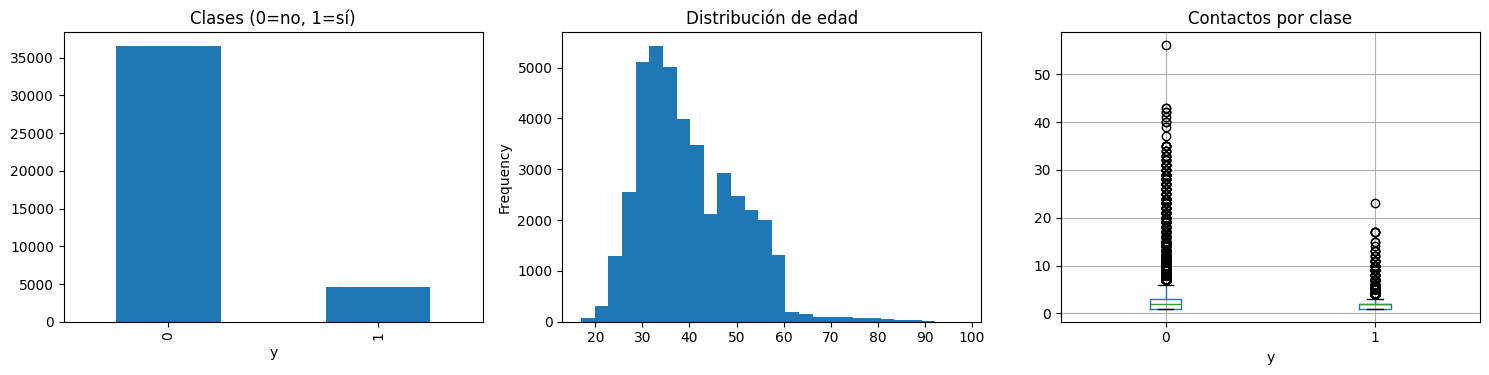

Tasa de contratación: 11.27 %


,size,mean
job,,
admin.,10419,0.129667
blue-collar,9253,0.068951
technician,6739,0.108325
services,3967,0.081422
management,2924,0.112175
retired,1718,0.252619
entrepreneur,1456,0.085165
self-employed,1421,0.104856
housemaid,1060,0.100000


In [4]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,3,figsize=(15,4))
clean['y'].value_counts().sort_index().plot.bar(ax=axes[0],title='Clases (0=no, 1=sí)')
clean['age'].plot.hist(bins=28,ax=axes[1],title='Distribución de edad')
clean.boxplot(column='campaign',by='y',ax=axes[2]);axes[2].set_title('Contactos por clase')
plt.suptitle('');plt.tight_layout();plt.savefig(ROOT/'resultados'/'eda.png',dpi=160);plt.show()
print('Tasa de contratación:',round(100*clean.y.mean(),2),'%')
display(clean.groupby('job',dropna=False)['y'].agg(['size','mean']).sort_values('size',ascending=False).head(12))

## 5. Diseño experimental

Se utiliza un hold-out estratificado 80/20 y cinco folds estratificados sobre entrenamiento. La regresión logística aporta un referente lineal interpretable; Random Forest modela relaciones no lineales y la SVM lineal ofrece otra función objetivo con regularización. La optimización toma ROC-AUC como métrica principal por su interpretación independiente del umbral de decisión; F1, precisión y sensibilidad complementan el análisis. `Pipeline` incluye imputación, escalado y codificación sin fuga entre folds.

In [5]:
from train import design_models,SEED
pre,models=design_models(clean)
print('Modelos y espacios de búsqueda:')
for name,(m,grid) in models.items():print(name,grid)
print('Semilla:',SEED,'| folds: 5 | selección: ROC-AUC')

Modelos y espacios de búsqueda:
regresion_logistica {'model__C': [0.1, 1, 10]}
random_forest {'model__n_estimators': [100, 200], 'model__max_depth': [8, 16], 'model__min_samples_leaf': [1, 5]}
svm_lineal {'model__C': [0.1, 1, 10]}
Semilla: 42 | folds: 5 | selección: ROC-AUC


## 6. Entrenamiento, evaluación y registro

Cada algoritmo se ajusta mediante GridSearchCV. Se registran hiperparámetros ganadores, métricas de entrenamiento cruzado y prueba final, matriz de confusión, curva ROC, resultados de búsqueda, hash del dataset y pipeline entrenado en MLflow. La ejecución puede tardar varios minutos en CPU. El conjunto de prueba no interviene en Grid Search.

In [6]:
from train import run_experiment
comparison,statistics,output=run_experiment(ROOT/'datos/datos_limp/bank_marketing_clean.csv',ROOT)
display(comparison)
print('Comparación estadística:',statistics)
print('Resultados guardados en:',output)

2026/10/19 03:33:05 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/19 03:33:05 INFO mlflow.store.db.utils: Updating database tables
2026/10/19 03:33:10 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_UCI_Bank_Marketing' does not exist. Creating a new experiment.


,modelo,accuracy,precision,recall,f1,roc_auc,cv_best_auc,train_seconds,cv_mean_auc,cv_std_auc,mejores_parametros
1,random_forest,0.869475,0.444021,0.628233,0.520303,0.812204,0.797855,465.584572,0.797855,0.010687,"{'model__max_depth': 16, 'model__min_samples_l..."
0,regresion_logistica,0.829407,0.357612,0.645474,0.460238,0.800298,0.790690,13.112070,0.790690,0.008584,{'model__C': 0.1}
2,svm_lineal,0.831714,0.362048,0.647629,0.464451,0.800305,0.790003,17.136726,0.790003,0.008339,{'model__C': 0.1}


Comparación estadística: {'comparacion': ['random_forest', 'regresion_logistica'], 'media_diferencia_auc': 0.007165705711090297, 'advertencia': 'Wilcoxon con 5 folds es exploratorio; dependencia entre folds y baja potencia.', 'wilcoxon_p': 0.0625}
Resultados guardados en: /content/Actividad5/resultados


## 7. Análisis comparativo y límites de inferencia

La decisión prioriza el promedio de ROC-AUC en validación cruzada. La prueba Wilcoxon de los cinco pares de folds se informa solo de manera **exploratoria**: los folds comparten muestras de entrenamiento, no son observaciones independientes, y cinco pares ofrecen baja potencia. No se inferirá superioridad poblacional solo por un p-valor pequeño. Las métricas de prueba final sirven para estimar capacidad de generalización, no para volver a optimizar.

,count,mean,std,min,25%,50%,75%,max
regresion_logistica,5.0,0.790690,0.008584,0.782061,0.784380,0.787322,0.798963,0.800722
random_forest,5.0,0.797855,0.010687,0.788193,0.790978,0.791145,0.808814,0.810146
svm_lineal,5.0,0.790003,0.008339,0.781659,0.784079,0.786457,0.797860,0.799960


,modelo,accuracy,precision,recall,f1,roc_auc,cv_best_auc,train_seconds,cv_mean_auc,cv_std_auc,mejores_parametros
0,random_forest,0.8695,0.4440,0.6282,0.5203,0.8122,0.7979,465.5846,0.7979,0.0107,"{'model__max_depth': 16, 'model__min_samples_l..."
1,regresion_logistica,0.8294,0.3576,0.6455,0.4602,0.8003,0.7907,13.1121,0.7907,0.0086,{'model__C': 0.1}
2,svm_lineal,0.8317,0.3620,0.6476,0.4645,0.8003,0.7900,17.1367,0.7900,0.0083,{'model__C': 0.1}


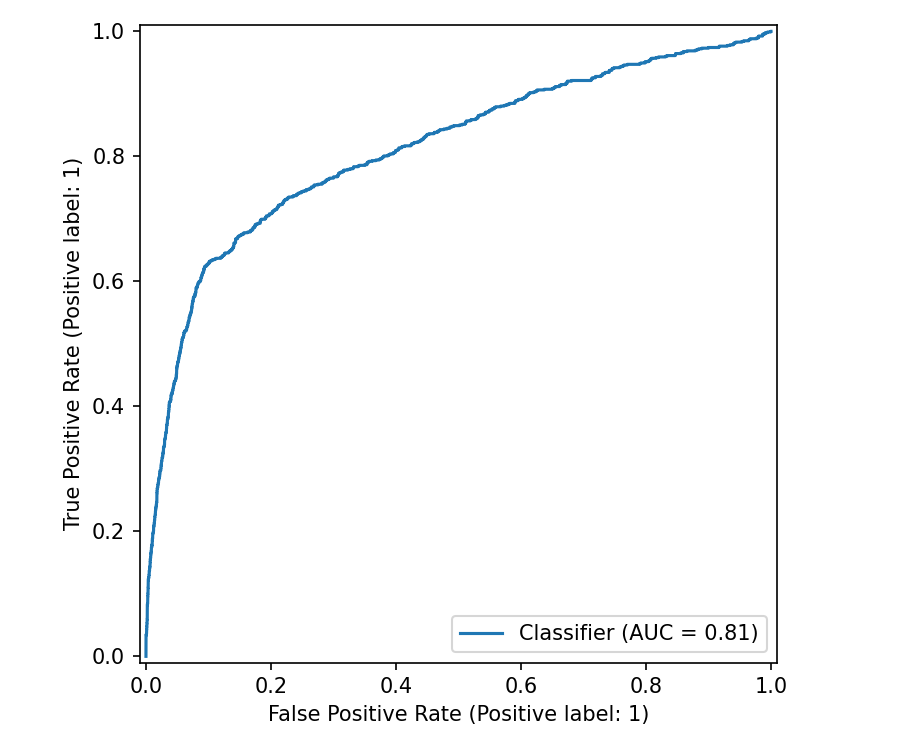

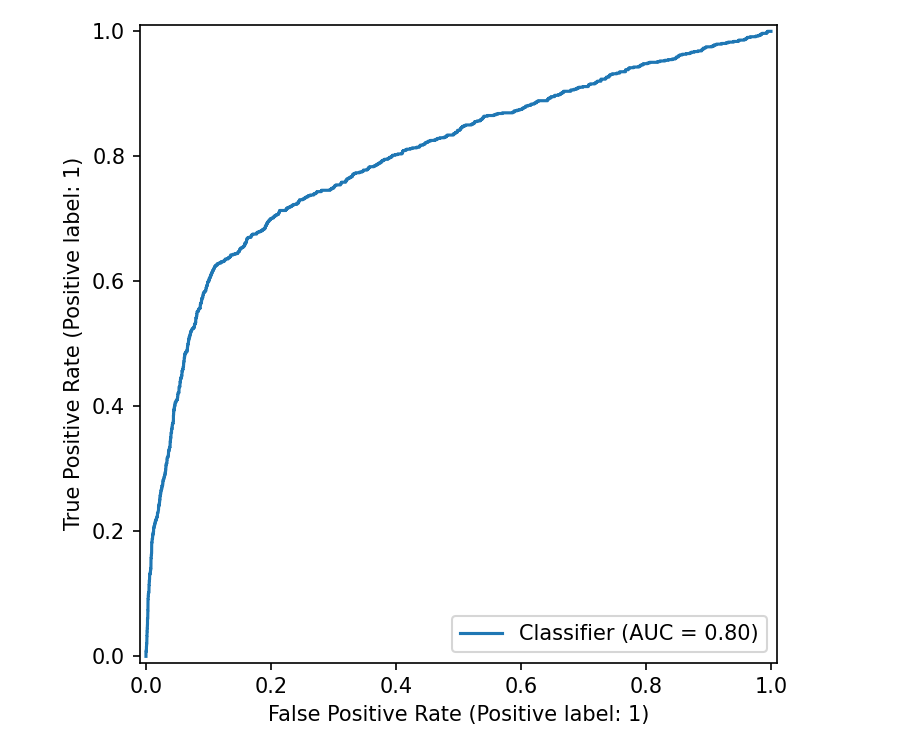

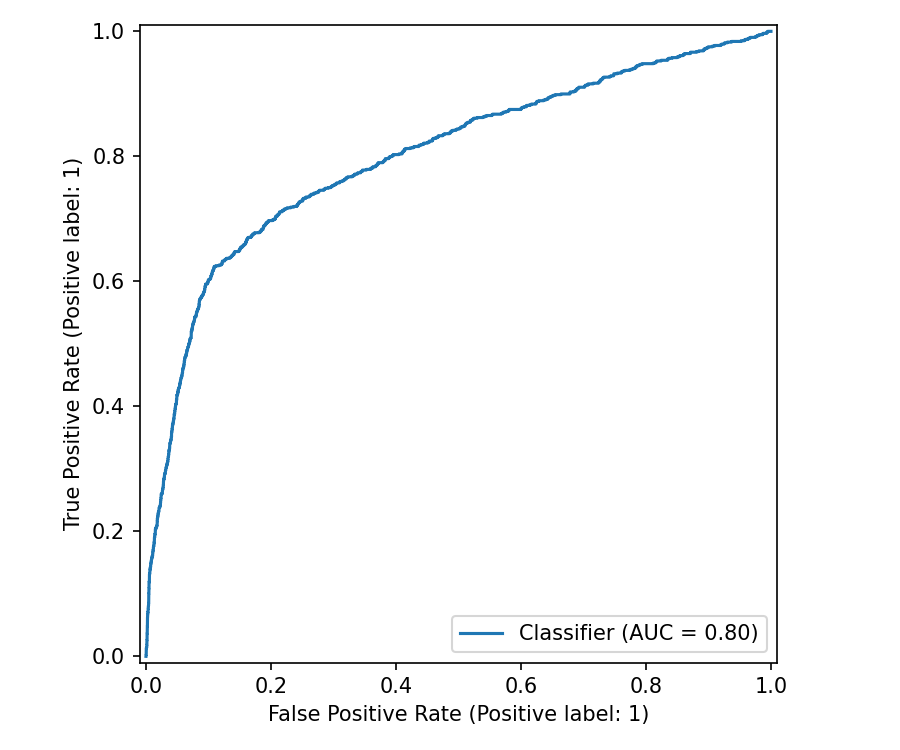

In [7]:
from IPython.display import display,Image
folds=pd.read_csv(ROOT/'resultados'/'metricas_por_fold.csv')
display(folds.describe().T)
display(pd.read_csv(ROOT/'resultados'/'comparacion_modelos.csv').round(4))
for image in sorted((ROOT/'resultados').glob('*_roc.png')):display(Image(filename=str(image),width=460))

## 8. Evidencia de experimentos MLflow

MLflow guarda metadatos de ejecución en SQLite (`mlflow.db`) y los artefactos en el almacenamiento local asociado. La interfaz web `localhost` no se abre directamente en Google Colab (documentación oficial de MLflow). La consulta siguiente comprueba de manera programática la existencia de ejecuciones registradas.

In [8]:
import mlflow
from mlflow.tracking import MlflowClient
client=MlflowClient(tracking_uri=f"sqlite:///{(ROOT/'mlflow.db').resolve().as_posix()}")
exp=client.get_experiment_by_name('Actividad5_UCI_Bank_Marketing')
assert exp is not None,'No existe experimento registrado'
runs=client.search_runs([exp.experiment_id],max_results=50)
assert len(runs)>=3,'Se esperaban tres runs, uno por modelo'
audit=pd.DataFrame([{'run_id':r.info.run_id,'modelo':r.data.params.get('model_name'),
                     'auc_cv':r.data.metrics.get('cv_mean_auc'),
                     'auc_test':r.data.metrics.get('roc_auc'),
                     'artefactos':[x.path for x in client.list_artifacts(r.info.run_id)]} for r in runs])
display(audit)
audit.to_csv(ROOT/'resultados'/'mlflow_runs_auditoria.csv',index=False)
print('Experimentos MLflow verificados:',len(runs))

,run_id,modelo,auc_cv,auc_test,artefactos
0,b3842f041e7e4124be2ac9fcfb028679,svm_lineal,0.790003,0.800305,"[cv_fold_auc.json, graficas, grid, search_setu..."
1,12db8fcae45a48ee9ee8cf41f809185f,random_forest,0.797855,0.812204,"[cv_fold_auc.json, graficas, grid, search_setu..."
2,05dc88ffa19646fb95bf4005ab0b1e3c,regresion_logistica,0.790690,0.800298,"[cv_fold_auc.json, graficas, grid, search_setu..."


Experimentos MLflow verificados: 3


## 9. Deuda técnica, reproducibilidad y producción

Los resultados no sustituyen validación en un banco real: la muestra es histórica, contiene variables asociadas a campañas específicas y el split aleatorio no evalúa cambios temporales. Para una solución operativa se necesitarían validaciones temporales, documentación de disponibilidad de variables, pruebas de integridad, seguimiento de drift y políticas de reentrenamiento. El versionamiento por Git y SHA256 y la centralización de los runs en MLflow reducen deuda de configuración, pero no equivalen a monitoreo productivo.

## 10. Conclusión metodológica y referencias

El modelo definitivo debe seleccionarse después de examinar los valores efectivamente obtenidos y su variabilidad entre folds. En esta ejecución, Random Forest obtuvo el mayor ROC-AUC y F1 en prueba. Sin embargo, la prueba de Wilcoxon no aporta evidencia suficiente de una diferencia significativa al umbral del 5 %, por lo que la selección es provisional y depende del objetivo operativo. En el reporte académico se deben insertar las gráficas y cifras generadas, discutir errores de clasificación y justificar el compromiso entre precisión, sensibilidad, costo y mantenibilidad.

**Referencias base (APA 7):**

- Dua, D., & Graff, C. (2019). *UCI Machine Learning Repository*. University of California, Irvine. https://archive.ics.uci.edu/
- MLflow Project. (s. f.). *MLflow tracking*. https://mlflow.org/docs/latest/tracking/
- scikit-learn developers. (s. f.). *GridSearchCV*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- Google Cloud. (s. f.). *MLOps: Continuous delivery and automation pipelines in machine learning*. https://cloud.google.com/architecture/mlops-continuous-delivery-and-automation-pipelines-in-machine-learning

**Nota:** completar el análisis numérico y las capturas únicamente tras ejecutar el notebook.